# NYC yellow taxi demand, 2024
Narrative walk-through of the analysis. All tables are read from `reports/tables`, produced by `python run_all.py`. Code for each step is in `src/` and `sql/`.

In [1]:
import json, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
T = '../reports/tables/'; F = '../reports/figures/'

## 1. Data and cleaning
Rules are applied in order; each dropped row is counted under the first rule it fails. `n_rows_failing` counts every row that fails the rule regardless of order. SQL: `sql/01_clean.sql`, `sql/02_rule_overlap.sql`.

In [2]:
pd.read_csv(T + 'cleaning_log.csv')

,rule,rows_dropped,n_rows_failing,pct_of_raw_dropped
0,r1_outside_file_month,420,420.0,0.001
1,r2_unknown_zone,146199,146201.0,0.355
2,r3_pickup_after_dropoff,1333,1575.0,0.003
3,r4_nonpositive_distance,754655,776305.0,1.833
4,r5_nonpositive_fare,685269,748284.0,1.664
5,r6_absurd_duration,143588,526919.0,0.349
6,r7_absurd_speed,2872,13245.0,0.007
7,TOTAL raw rows loaded,41169720,NaN,NaN
8,TOTAL dropped,1734336,NaN,4.213
9,TOTAL rows after cleaning,39435384,NaN,NaN


## 2. Hourly aggregation
`sql/03_aggregate_hourly.sql` builds a zero-filled zone x hour grid (263 zones x 8,784 hours). Timestamps are naive local time, so the DST spring-forward hour has no trips and the fall-back hour contains two clock hours; the citywide series is adjusted for both:

In [3]:
pd.read_csv(T + 'dst_adjustments.csv')

,hour,raw,adjusted,reason
0,2024-03-10 02:00:00,0.0,4429.5,DST start: hour does not exist
1,2024-11-03 01:00:00,8423.0,4211.5,DST end: two clock hours merged


## 3. EDA
Mean pickups by weekday and hour:

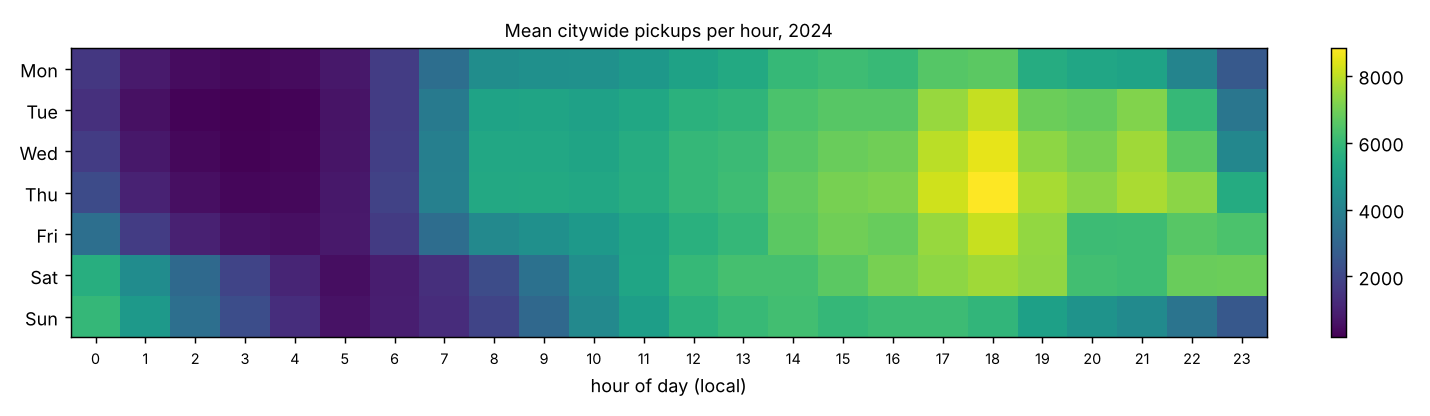

In [4]:
display(Image(F + 'hour_dow_heatmap.png'))

Borough totals and hour-of-day profiles (weekday vs weekend):

,borough,pickups,n_zones,share_pct
0,Manhattan,35162734.0,69,89.165441
1,Queens,3606840.0,69,9.146202
2,Brooklyn,551026.0,61,1.397288
3,Bronx,113056.0,43,0.286687
4,Staten Island,1393.0,20,0.003532
5,EWR,335.0,1,0.000849


,borough,day_type,peak_hour,peak_mean_pickups,trough_hour,trough_mean_pickups
0,Manhattan,weekday,18,7377.748092,3,305.889313
1,Manhattan,weekend,17,6045.057692,5,429.028846
2,Queens,weekday,16,714.637405,3,30.500000
3,Queens,weekend,16,666.836538,3,45.298077
4,Brooklyn,weekday,8,119.839695,2,7.908397
5,Brooklyn,weekend,0,148.711538,5,32.278846
6,Bronx,weekday,7,34.992366,2,1.534351
7,Bronx,weekend,9,20.269231,2,2.663462


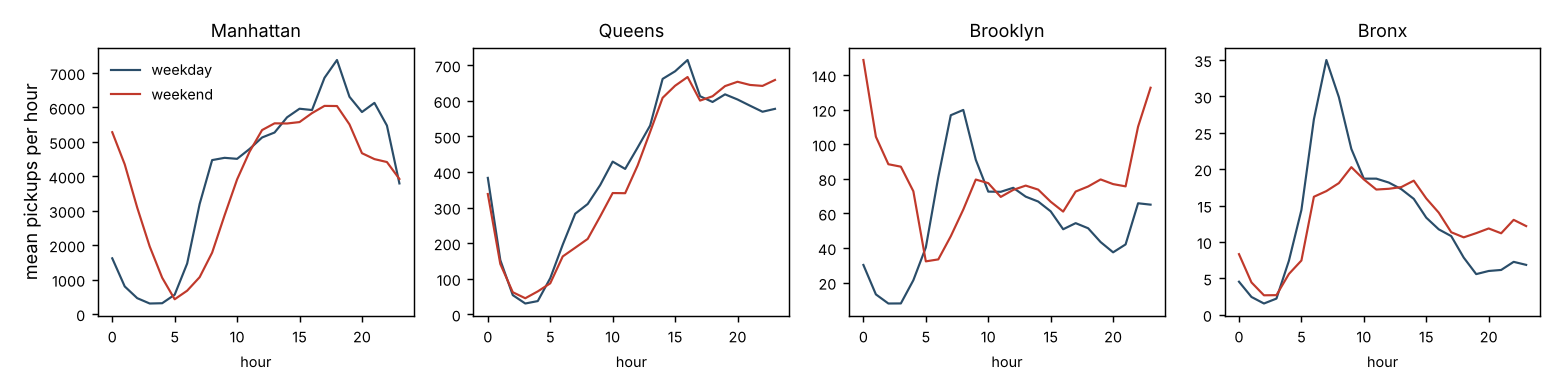

In [5]:
display(pd.read_csv(T + 'eda_borough_totals.csv'))
display(pd.read_csv(T + 'eda_borough_peaks.csv'))
display(Image(F + 'borough_hour_profiles.png'))

Zone concentration and holidays (holiday total vs mean of the same weekday 1-3 weeks before/after):

,airports_jfk_lga_share_of_queens_pct,airports_jfk_lga_share_of_all_pct,zones_total,zones_with_any_pickup,top10_share_pct,zones_for_80pct
0,86.093644,7.874299,263,261,37.955355,31


,date,holiday,weekday,pickups,same_weekday_mean,n_comparison_days,pct_diff
0,2024-01-01,New Year's Day,Monday,74799,79804.500000,2,-6.272203
1,2024-01-15,Martin Luther King Jr. Day,Monday,74162,81644.500000,4,-9.164732
2,2024-02-19,Washington's Birthday,Monday,72811,87164.833333,6,-16.467459
3,2024-05-27,Memorial Day,Monday,69570,102304.666667,6,-31.997237
4,2024-06-19,Juneteenth National Independence Day,Wednesday,99457,114040.833333,6,-12.788256
5,2024-07-04,Independence Day,Thursday,58935,117491.333333,6,-49.838853
6,2024-09-02,Labor Day,Monday,76865,91847.666667,6,-16.312517
7,2024-10-14,Columbus Day,Monday,97208,101622.500000,6,-4.344018
8,2024-11-11,Veterans Day,Monday,95986,103366.666667,6,-7.140277
9,2024-11-28,Thanksgiving Day,Thursday,73729,139262.333333,6,-47.057472


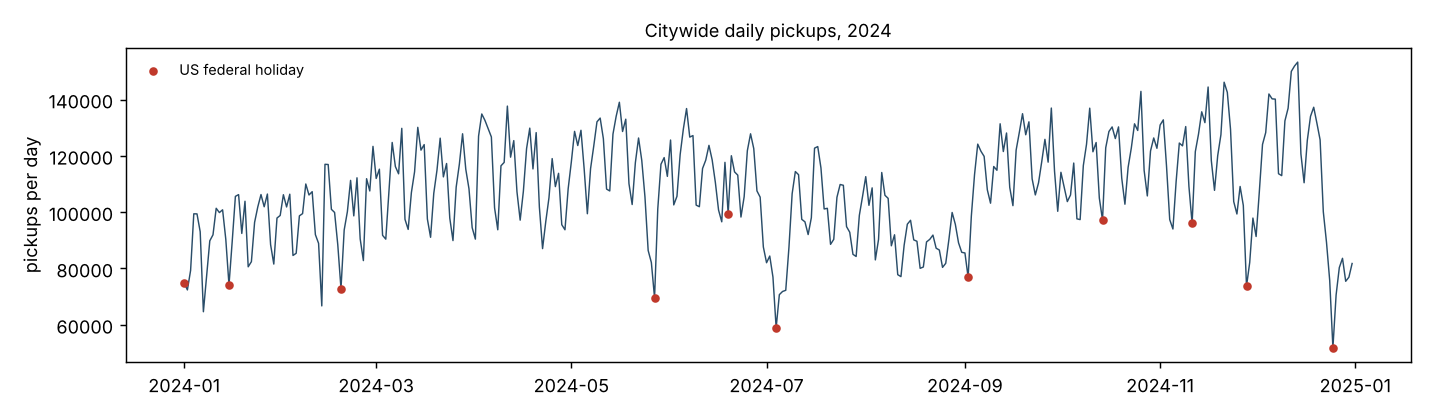

In [6]:
display(pd.read_csv(T + 'eda_zone_concentration.csv'))
display(pd.read_csv(T + 'eda_holiday_effects.csv'))
display(Image(F + 'daily_pickups_holidays.png'))

## 4. Time series: citywide hourly demand
MSTL decomposition of log pickups with daily (24h) and weekly (168h) periods. Strength of a component is `1 - Var(resid) / Var(component + resid)`.

In [7]:
meta = json.load(open(T + 'forecast_meta.json')); meta

{'sarima_order': [2, 0, 1],
 'seasonal_order': [0, 1, 1, 24],
 'fourier_k': 6,
 'n_folds': 12,
 'series_hours': 8784,
 'calendar_sarima_resid_order': [[2, 0, 1], [1, 0, 1, 24]],
 'example_fold': 11,
 'sarimax_folds_converged': 12,
 'strength_daily': 0.9817212874376854,
 'strength_weekly': 0.9190153405829952,
 'strength_trend': 0.5613911903193705}

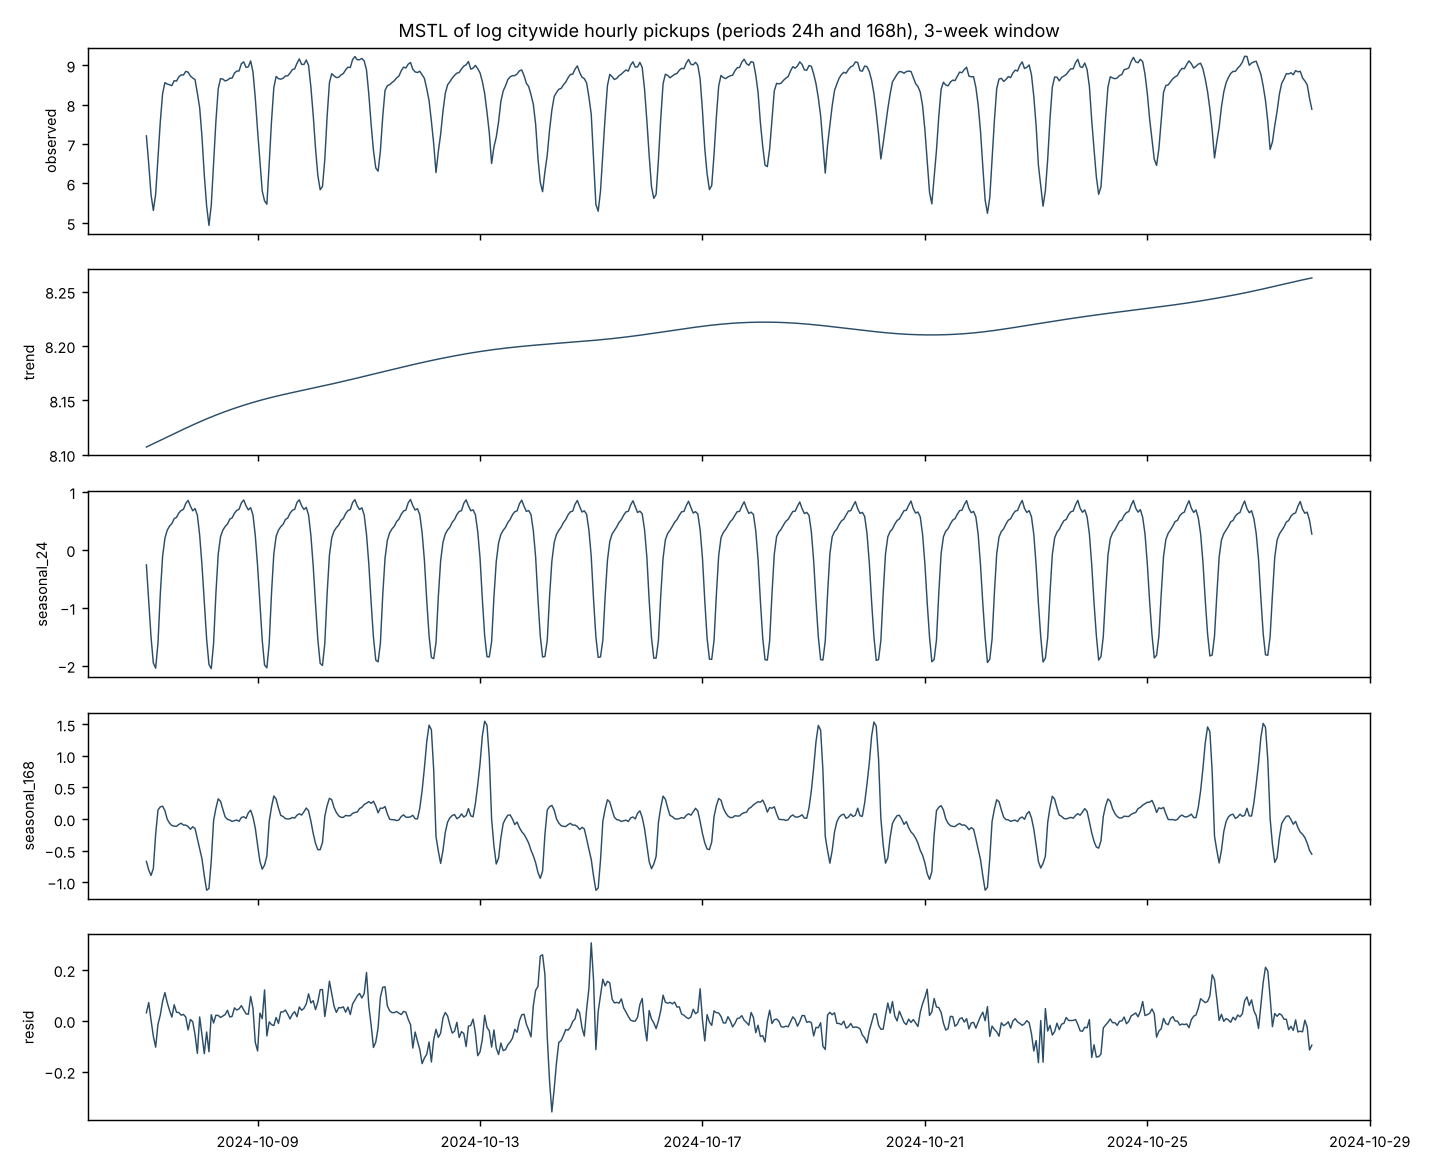

In [8]:
display(Image(F + 'stl_decomposition.png'))

Rolling-origin evaluation (expanding window). Each origin forecasts 168 hours; the 24h horizon is the first 24 of them. MASE uses the in-sample MAE of the lag-168 seasonal naive as the scale. SARIMA order chosen by AIC on the first fold's training data only:

In [9]:
pd.read_csv(T + 'sarima_order_selection.csv')

,p,d,q,aic,model,order,seasonal_order
0,2.0,0.0,1.0,-1789.006302,sarimax,NaN,NaN
1,2.0,0.0,0.0,-1722.904285,sarimax,NaN,NaN
2,1.0,0.0,1.0,-747.822775,sarimax,NaN,NaN
3,1.0,0.0,0.0,-153.429821,sarimax,NaN,NaN
4,NaN,NaN,NaN,-4555.695460,calendar_sarima,"(2, 0, 1)","(1, 0, 1, 24)"
5,NaN,NaN,NaN,-4541.236193,calendar_sarima,"(2, 0, 1)","(1, 0, 0, 24)"
6,NaN,NaN,NaN,-4529.491953,calendar_sarima,"(2, 0, 0)","(1, 0, 0, 24)"
7,NaN,NaN,NaN,-4497.121072,calendar_sarima,"(1, 0, 0)","(1, 0, 0, 24)"


In [10]:
pd.read_csv(T + 'forecast_summary.csv').round(3)

,horizon,model,MAE,sMAPE,MASE,MASE_sd,folds,folds_beating_snaive_168,median_fold_MAE_ratio,MAE_ratio_vs_snaive_168
0,24,snaive_168,450.028,11.720,0.860,0.719,12,0,1.000,1.000
1,24,calendar_sarima,463.300,11.482,0.880,0.655,12,4,1.141,1.029
2,24,calendar_ols,732.637,16.289,1.387,0.983,12,1,1.656,1.628
3,24,snaive_24,860.427,27.813,1.690,0.928,12,2,2.122,1.912
4,24,sarimax,914.444,26.380,1.753,1.078,12,3,2.764,2.032
5,168,calendar_sarima,538.695,12.952,1.035,0.266,12,7,0.904,0.924
6,168,snaive_168,583.317,15.068,1.130,0.551,12,0,1.000,1.000
7,168,calendar_ols,660.604,15.171,1.263,0.444,12,6,1.094,1.132
8,168,sarimax,958.528,27.293,1.864,0.310,12,1,1.906,1.643
9,168,snaive_24,1254.088,37.419,2.446,0.889,12,0,2.159,2.150


In [11]:
pd.read_csv(T + 'forecast_metrics_by_fold.csv').pivot_table(index=['fold','origin'], columns=['horizon','model'], values='MASE').round(3)

horizon                  24                                                        168                                             
model           calendar_ols calendar_sarima sarimax snaive_168 snaive_24 calendar_ols calendar_sarima sarimax snaive_168 snaive_24
fold origin                                                                                                                        
1    2024-04-01        0.748           0.527   0.895      0.343     2.617        1.068           1.058   2.439      1.285     4.286
2    2024-04-20        0.762           0.619   1.778      0.960     2.457        1.572           1.453   1.911      0.999     2.024
3    2024-05-09        0.767           0.610   1.612      0.552     0.859        0.755           0.758   2.272      0.889     1.796
4    2024-05-28        1.586           0.802   1.059      1.481     3.433        1.143           0.721   2.075      2.000     4.039
5    2024-06-16        1.152           0.806   2.518      0.640     1.109        1.226           1.034   1.750      0.860     1.969
6    2024-07-05        4.266           2.930   4.471      2.824     1.444        2.316           1.447   2.029      2.377     2.942
7    2024-07-24        1.017           0.627   0.948      0.996     0.463        1.407           1.182   1.405      0.572     1.544
8    2024-08-12        1.521           0.873   0.601      1.014     1.951        1.770           1.240   1.482      0.898     2.279
9    2024-08-31        1.884           0.860   1.627      0.255     1.137        0.905           1.034   1.558      1.277     1.819
10   2024-09-19        1.143           0.589   1.226      0.336     0.632        1.134           0.852   1.900      0.593     1.872
11   2024-10-08        0.647           0.650   1.446      0.349     1.548        1.000           1.015   1.717      1.102     2.148
12   2024-10-27        1.155           0.671   2.851      0.570     2.626        0.864           0.632   1.832      0.712     2.629

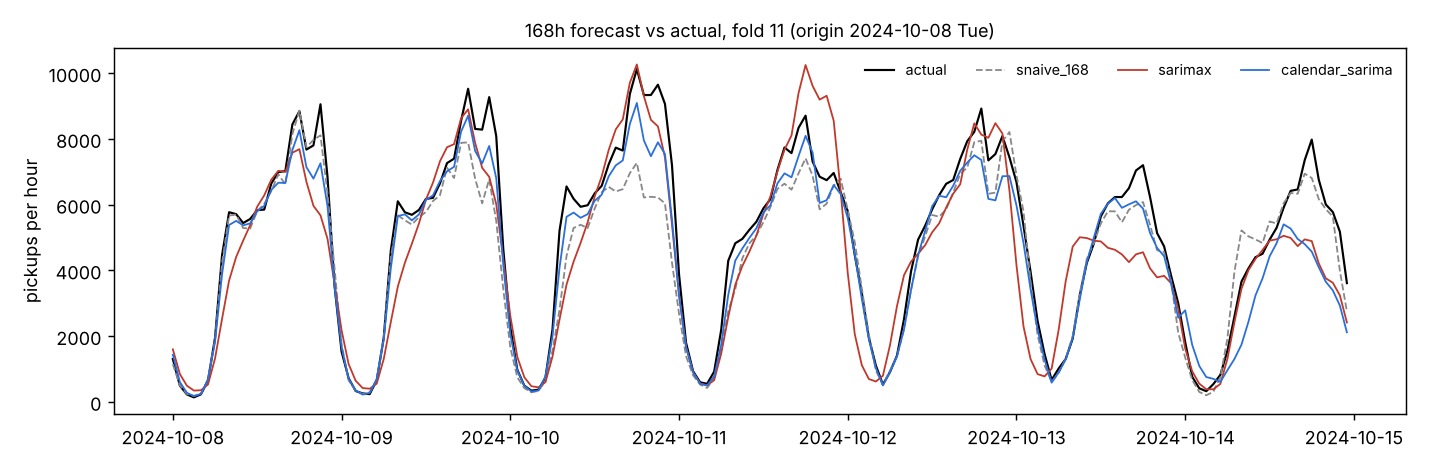

In [12]:
display(Image(F + 'forecast_example_fold.png'))

Residual diagnostics, models fitted on the full year (Ljung-Box H0: no autocorrelation up to the lag):

,model,lag,lb_stat,lb_pvalue,max_abs_acf_1_200,lag_of_max_acf
0,sarimax,24,1326.787028,2.174882e-265,0.555151,168
1,sarimax,48,2214.680403,0.000000e+00,0.555151,168
2,sarimax,168,9429.389556,0.000000e+00,0.555151,168
3,calendar_ols,24,51341.308154,0.000000e+00,0.878514,1
4,calendar_ols,48,80930.245425,0.000000e+00,0.878514,1
5,calendar_ols,168,133461.814469,0.000000e+00,0.878514,1
6,calendar_sarima,24,329.718058,1.657710e-55,0.120007,23
7,calendar_sarima,48,486.250449,8.252940e-74,0.120007,23
8,calendar_sarima,168,901.799483,9.064640e-101,0.120007,23


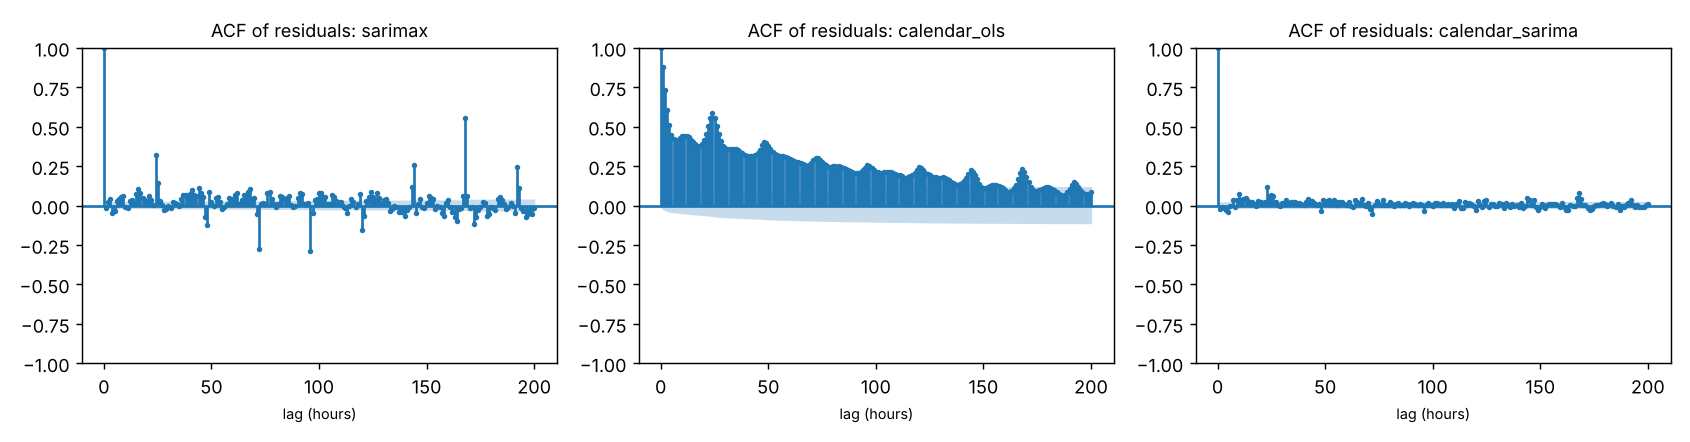

In [13]:
display(pd.read_csv(T + 'residual_ljungbox.csv'))
display(Image(F + 'residual_acf.png'))

## 5. Inference
### 5a. Logit: is a zone-hour above its zone's 75th percentile?
Zones with at least 10 pickups/day on average. Standard errors are cluster-robust, two-way by zone and date, because zone-hours from the same zone or the same day are not independent.

In [14]:
c = pd.read_csv(T + 'logit_coefficients.csv')
display(c.drop(columns='reading').round(4))
for r in c.itertuples(): print('-', r.term + ':', r.reading)

,term,coef,se_cluster,z,p_value,ci_low,ci_high,odds_ratio,or_ci_low,or_ci_high
0,const,-0.9562,0.0761,-12.5655,0.0000,-1.1054,-0.8071,0.3843,0.3311,0.4462
1,block[night_00_05],-1.5326,0.1524,-10.0536,0.0000,-1.8314,-1.2339,0.2160,0.1602,0.2912
2,block[am_peak_06_09],-0.1043,0.0943,-1.1068,0.2684,-0.2891,0.0804,0.9009,0.7489,1.0838
3,block[pm_peak_16_19],0.2903,0.0882,3.2899,0.0010,0.1174,0.4632,1.3368,1.1245,1.5892
4,block[evening_20_23],-0.0977,0.1287,-0.7593,0.4476,-0.3500,0.1545,0.9069,0.7047,1.1671
5,weekend,0.1519,0.0907,1.6741,0.0941,-0.0259,0.3297,1.1640,0.9744,1.3906
6,holiday,-0.5296,0.1643,-3.2228,0.0013,-0.8517,-0.2075,0.5888,0.4267,0.8126
7,borough[Bronx],-0.7559,0.0992,-7.6216,0.0000,-0.9503,-0.5615,0.4696,0.3866,0.5704
8,borough[Brooklyn],-0.3835,0.0601,-6.3835,0.0000,-0.5012,-0.2657,0.6815,0.6058,0.7666
9,borough[Queens],-0.5180,0.0831,-6.2313,0.0000,-0.6809,-0.3551,0.5957,0.5062,0.7011


- const: Reference case (weekday, non-holiday, midday_10_15, Manhattan): odds 0.38, i.e. predicted probability 0.28 that a zone-hour is above its zone's 75th percentile.
- block[night_00_05]: Odds of a high-demand zone-hour in hour block night_00_05 are 0.22 times the odds for hour block midday_10_15 (95% CI 0.16 to 0.29), other predictors held fixed.
- block[am_peak_06_09]: Odds of a high-demand zone-hour in hour block am_peak_06_09 are 0.90 times the odds for hour block midday_10_15 (95% CI 0.75 to 1.08), other predictors held fixed. The CI includes 1, so there is no clear effect.
- block[pm_peak_16_19]: Odds of a high-demand zone-hour in hour block pm_peak_16_19 are 1.34 times the odds for hour block midday_10_15 (95% CI 1.12 to 1.59), other predictors held fixed.
- block[evening_20_23]: Odds of a high-demand zone-hour in hour block evening_20_23 are 0.91 times the odds for hour block midday_10_15 (95% CI 0.70 to 1.17), other predictors held fixed. The CI includes 1, so there is no 

In [15]:
display(pd.read_csv(T + 'logit_vif.csv').round(3))
inf = json.load(open(T + 'inference_meta.json')); inf['logit']

,term,VIF
0,block[night_00_05],1.497
1,block[am_peak_06_09],1.388
2,block[pm_peak_16_19],1.385
3,block[evening_20_23],1.385
4,weekend,1.013
5,holiday,1.013
6,borough[Bronx],1.083
7,borough[Brooklyn],1.193
8,borough[Queens],1.181


{'n_rows': 1256112,
 'n_zones': 143,
 'positive_rate': 0.19493882711095825,
 'pseudo_r2': 0.05971705529784921,
 'boroughs': ['Bronx', 'Brooklyn', 'Manhattan', 'Queens'],
 'cov_type': 'cluster-robust, two-way (zone, date)',
 'calib_holdout_rows': 315744,
 'calib_brier': 0.17170436225342522,
 'calib_brier_constant_train_rate': 0.18311032720112452,
 'calib_auc': 0.6683489431894472,
 'calib_holdout_positive_rate': 0.23570044086348435,
 'calib_mean_predicted_holdout': 0.1798988551705943,
 'calib_n_bins': 10,
 'calib_max_abs_bin_gap': 0.20482518869611416}

Calibration on a time holdout (fit January-September, predict October-December):

,bin,n,mean_predicted,observed_rate
0,"(0.018099999999999998, 0.0477]",35496,0.043,0.057
1,"(0.0477, 0.072]",33924,0.065,0.076
2,"(0.072, 0.148]",26116,0.110,0.196
3,"(0.148, 0.172]",31948,0.164,0.208
4,"(0.172, 0.185]",42036,0.179,0.295
5,"(0.185, 0.205]",23216,0.195,0.257
6,"(0.205, 0.243]",37248,0.236,0.189
7,"(0.243, 0.261]",42084,0.256,0.340
8,"(0.261, 0.273]",12688,0.270,0.164
9,"(0.273, 0.353]",30988,0.319,0.524


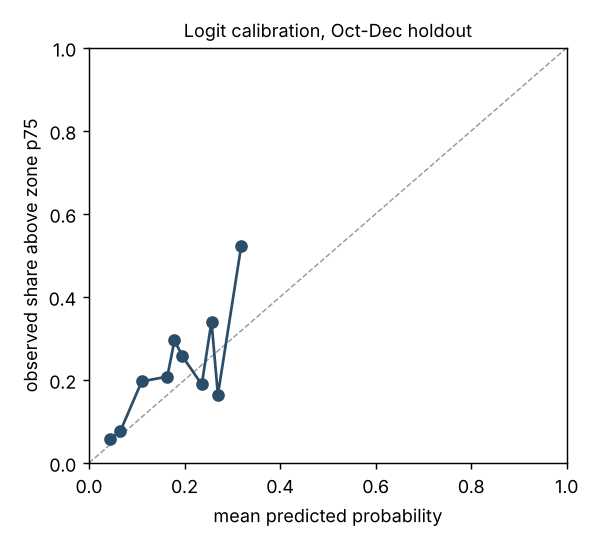

In [16]:
display(pd.read_csv(T + 'logit_calibration.csv').round(3))
display(Image(F + 'logit_calibration.png'))

### 5b. Weekday vs weekend daily pickups, per zone
Holidays excluded. Test choice is decided by a rule fixed in code before the tests run: if more than 20% of zones reject normality (Shapiro-Wilk) in either group, use Mann-Whitney U; otherwise Welch's t-test. Benjamini-Hochberg FDR at 5%.

In [17]:
inf['tests']

{'n_zones_tested': 143,
 'primary_test': 'Mann-Whitney U',
 'share_zones_nonnormal_shapiro': 0.8601398601398601,
 'median_abs_skew': 0.48829762948209365,
 'n_sig_raw': 116,
 'n_sig_bh': 114,
 'n_null_bh': 29,
 'n_sig_bh_weekend_higher': 62,
 'n_sig_bh_weekend_lower': 52,
 'n_sig_bh_other_test': 111,
 'agreement_primary_vs_other': 0.951048951048951}

In [18]:
t = pd.read_csv(T + 'weekday_weekend_tests.csv')
cols = ['zone_name','borough','daily_mean','ratio_weekend_weekday','ratio_ci_low','ratio_ci_high','rank_biserial','p_primary','q_bh','reject_bh']
print('Largest weekend drop'); display(t.sort_values('ratio_weekend_weekday')[cols].head(8).round(3))
print('Largest weekend lift'); display(t.sort_values('ratio_weekend_weekday')[cols].tail(8).round(3))
print('Not significant after BH'); display(t[~t.reject_bh][cols].round(3))

Largest weekend drop


,zone_name,borough,daily_mean,ratio_weekend_weekday,ratio_ci_low,ratio_ci_high,rank_biserial,p_primary,q_bh,reject_bh
10,Midwood,Brooklyn,11.948,0.342,0.297,0.391,-0.887,0.0,0.0,True
25,Borough Park,Brooklyn,10.948,0.434,0.358,0.522,-0.693,0.0,0.0,True
19,Sheepshead Bay,Brooklyn,10.776,0.496,0.440,0.555,-0.748,0.0,0.0,True
1,Lenox Hill East,Manhattan,2130.079,0.548,0.524,0.572,-0.971,0.0,0.0,True
35,Coney Island,Brooklyn,15.085,0.565,0.496,0.634,-0.638,0.0,0.0,True
32,Flatlands,Brooklyn,25.497,0.587,0.526,0.647,-0.661,0.0,0.0,True
6,Midtown Center,Manhattan,5075.199,0.614,0.587,0.639,-0.911,0.0,0.0,True
39,Marine Park/Mill Basin,Brooklyn,11.342,0.622,0.556,0.688,-0.580,0.0,0.0,True


Largest weekend lift


,zone_name,borough,daily_mean,ratio_weekend_weekday,ratio_ci_low,ratio_ci_high,rank_biserial,p_primary,q_bh,reject_bh
5,Alphabet City,Manhattan,182.117,2.914,2.683,3.180,0.913,0.0,0.0,True
11,Williamsburg (South Side),Brooklyn,59.005,3.521,3.139,3.943,0.878,0.0,0.0,True
15,Maspeth,Queens,18.571,3.739,3.238,4.301,0.804,0.0,0.0,True
13,Greenpoint,Brooklyn,41.691,3.742,3.296,4.224,0.866,0.0,0.0,True
33,Red Hook,Brooklyn,21.858,4.310,3.417,5.471,0.650,0.0,0.0,True
12,Bushwick North,Brooklyn,22.199,4.567,3.955,5.249,0.875,0.0,0.0,True
4,Williamsburg (North Side),Brooklyn,84.943,4.837,4.280,5.452,0.926,0.0,0.0,True
2,East Williamsburg,Brooklyn,50.281,5.371,4.715,6.108,0.924,0.0,0.0,True


Not significant after BH


,zone_name,borough,daily_mean,ratio_weekend_weekday,ratio_ci_low,ratio_ci_high,rank_biserial,p_primary,q_bh,reject_bh
114,Springfield Gardens South,Queens,16.557,0.922,0.850,0.994,-0.137,0.042,0.053,False
115,University Heights/Morris Heights,Bronx,10.781,0.935,0.841,1.033,-0.135,0.044,0.055,False
116,Erasmus,Brooklyn,14.820,0.937,0.822,1.055,-0.125,0.063,0.078,False
117,Washington Heights South,Manhattan,85.533,0.936,0.839,1.036,-0.123,0.069,0.084,False
118,Brooklyn Heights,Brooklyn,76.396,1.117,1.007,1.232,0.119,0.077,0.092,False
119,Kew Gardens,Queens,12.940,0.924,0.840,1.010,-0.107,0.112,0.134,False
120,JFK Airport,Queens,5051.060,1.031,0.991,1.074,0.091,0.179,0.211,False
121,Rego Park,Queens,11.148,1.117,1.010,1.239,0.086,0.199,0.233,False
122,Melrose South,Bronx,14.672,1.099,0.989,1.231,0.086,0.204,0.237,False
123,Baisley Park,Queens,37.145,1.052,0.990,1.117,0.085,0.209,0.241,False


## 6. Findings
See `reports/findings.md` (also shown in the dashboard) and the README.